## Examining Diabetes and COVID-19 data

## Step 1: Load the data

**Why:** You should always look at a dataset before analyzing it. This is how I found out the file has three versions of the data stacked together and "All Ages" total rows, which would cause double counting if I didn't filter them out. I also used `thousands=","` because the file writes numbers with commas ("1,569"), which made pandas read them as text and my first totals came out as 0.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("covid_conditions.csv", thousands=",")

# how many rows and columns
print(df.shape)           
#column names
print(df.columns.tolist())     
#different "Group" values
print(df["Group"].unique())
# different age groups
print(df["Age Group"].unique())

(621000, 14)
['Data As Of', 'Start Date', 'End Date', 'Group', 'Year', 'Month', 'State', 'Condition Group', 'Condition', 'ICD10_codes', 'Age Group', 'COVID-19 Deaths', 'Number of Mentions', 'Flag']
<ArrowStringArray>
['By Total', 'By Year', 'By Month']
Length: 3, dtype: str
<ArrowStringArray>
[      '0-24',      '25-34',      '35-44',      '45-54',      '55-64',
      '65-74',      '75-84',        '85+', 'Not stated',   'All Ages']
Length: 10, dtype: str


**What the results mean:** The file has 621,000 rows and 14 columns. "Group" has three values (By Total, By Year, By Month), and "Age Group" has eight age ranges plus "Not stated" and an "All Ages" total.

## Step 2: Clean the data

**Why:** The same deaths appear in By Total, By Year, and By Month. Using all three would count every death three times. By Total covers the full 2020-2023 period in one row. Blank counts stay empty instead of 0, because the CDC hides counts between 1 and 9 for privacy, so a blank means "small," not zero.

In [2]:
# The file stacks the same data three ways: By Total, By Year, By Month.
# We only want the full 2020-2023 totals
df = df[df["Group"] == "By Total"]

# Ensure the death counts are numbers (blanks become empty, not zero)
df["COVID-19 Deaths"] = pd.to_numeric(df["COVID-19 Deaths"], errors="coerce")

## Step 3: How common was diabetes compared to other conditions?

**Why:** Percents put every condition on the same scale, so I can see how diabetes ranks. I removed "All other conditions" because it's a catch-all bucket, not a real condition. One death can list several conditions, so the percents add up to more than 100%.

In [3]:
# National numbers, all ages
national = df[(df["State"] == "United States") & (df["Age Group"] == "All Ages")]

# Total COVID-19 deaths
total_covid = national[national["Condition"] == "COVID-19"]["COVID-19 Deaths"].sum()
print("Total COVID-19 deaths:", total_covid)

# Percent of COVID deaths that listed each condition
conditions = national[national["Condition"] != "COVID-19"].copy()
conditions["Percent"] = conditions["COVID-19 Deaths"] / total_covid * 100
conditions = conditions.sort_values("Percent", ascending=False)

conditions[["Condition", "COVID-19 Deaths", "Percent"]].head(10)

Total COVID-19 deaths: 1146242.0


,Condition,COVID-19 Deaths,Percent
9,Influenza and pneumonia,531174.0,46.340476
219,All other conditions and causes (residual),477521.0,41.659702
39,Respiratory failure,436333.0,38.066394
69,Hypertensive diseases,213709.0,18.644318
159,Diabetes,168830.0,14.729001
89,Cardiac arrest,135478.0,11.819319
199,Renal failure,129674.0,11.312969
79,Ischemic heart disease,128178.0,11.182455
139,Sepsis,119000.0,10.381752
19,Chronic lower respiratory diseases,109697.0,9.570143


**What the results mean:**
- There were **1,146,242** COVID-19 deaths in the U.S. from 2020 to 2023.
- Diabetes was listed on **168,830 (14.7%)**, about **1 in 7**.
- The top two, influenza/pneumonia (46.3%) and respiratory failure (38.1%), are mostly **complications caused by COVID itself**. Among **chronic conditions people already had**, diabetes is **#2**, behind only hypertension (18.6%).

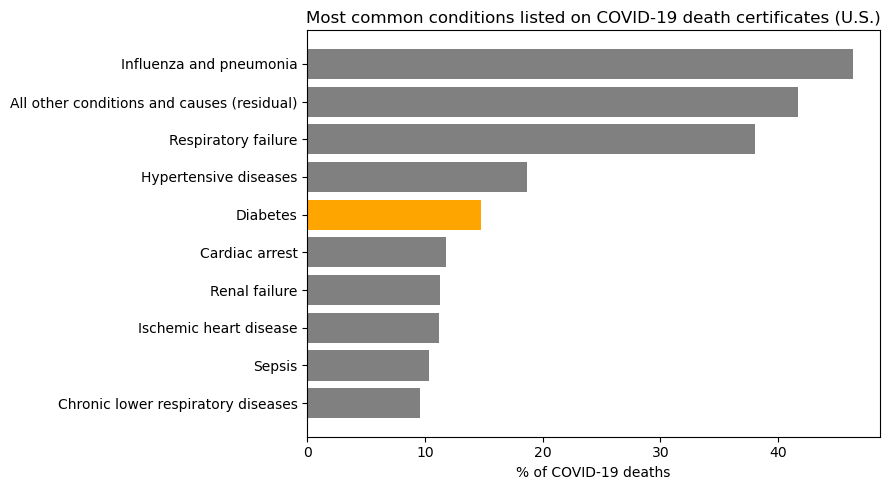

In [8]:
top10 = conditions.head(10)
colors = ["orange" if c == "Diabetes" else "gray" for c in top10["Condition"]]

plt.figure(figsize=(9, 5))
plt.barh(top10["Condition"], top10["Percent"], color=colors)
plt.gca().invert_yaxis() 
plt.title("Most common conditions listed on COVID-19 death certificates (U.S.)")
plt.xlabel("% of COVID-19 deaths")
plt.tight_layout()
plt.savefig("chart1_top_conditions.png")
plt.show()

## Step 4: Diabetes by age group

I kept only the Diabetes and total COVID-19 rows for the U.S., and dropped the "All Ages" total and "Not stated" rows so nothing was double counted.

A pivot table puts diabetes deaths and total COVID-19 deaths side by side for each age group, so I can divide one by the other.

In [9]:
# U.S. only, just the Diabetes and total COVID-19 rows
us = df[(df["State"] == "United States") & (df["Condition"].isin(["Diabetes", "COVID-19"]))]
us = us[~us["Age Group"].isin(["All Ages", "Not stated"])]   # drop the total and unknown rows

# Put Diabetes and COVID-19 side by side (like an Excel pivot table)
by_age = us.pivot_table(index="Age Group", columns="Condition", values="COVID-19 Deaths")
by_age["Percent with Diabetes"] = by_age["Diabetes"] / by_age["COVID-19"] * 100
by_age

Condition,COVID-19,Diabetes,Percent with Diabetes
Age Group,,,
0-24,4320.0,289.0,6.689815
25-34,12354.0,1252.0,10.134369
35-44,30071.0,4295.0,14.282864
45-54,71364.0,12297.0,17.231377
55-64,159656.0,28768.0,18.018740
65-74,256711.0,45930.0,17.891715
75-84,300009.0,45442.0,15.146879
85+,311734.0,30553.0,9.800984


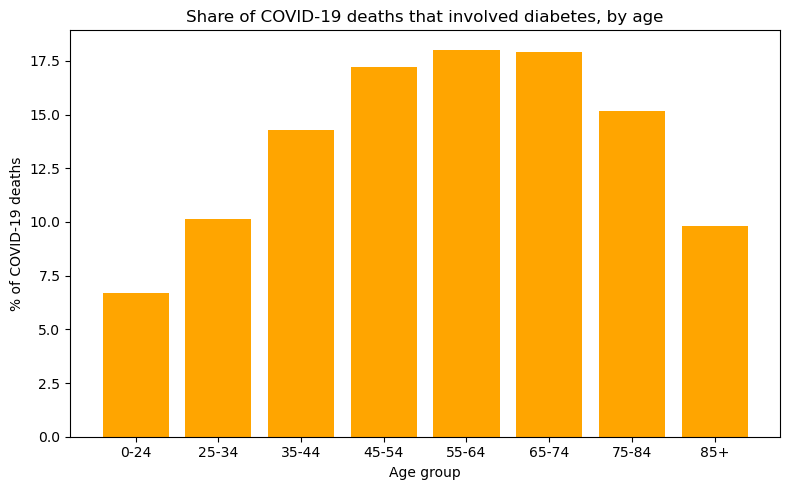

In [12]:
plt.figure(figsize=(8, 5))
plt.bar(by_age.index, by_age["Percent with Diabetes"], color="orange")
plt.title("Share of COVID-19 deaths that involved diabetes, by age")
plt.xlabel("Age group")
plt.ylabel("% of COVID-19 deaths")
plt.tight_layout()
plt.savefig("chart2_by_age.png")
plt.show()

### Findings

- The share of COVID-19 deaths involving diabetes **peaks in middle age**: 17.2% for ages 45-54, **18.0% for ages 55-64**, and 17.9% for ages 65-74.
- It drops to **9.8% for ages 85+**, even though that group had the most deaths (311,734).
- **Why this matters:** older people were at high risk from COVID no matter what. Middle-aged people who died were more likely to have a chronic condition like diabetes adding to their risk.
- The age groups add up to the national total (168,826 vs 168,830; the small gap is from "Not stated"), which confirms the filters worked.

## Step 5: Diabetes by state

Same approach as the age breakdown, but by state, using the "All Ages" rows. Note that the CDC lists **New York City separately** from New York State.

In [13]:
st = df[(df["State"] != "United States")
        & (df["Age Group"] == "All Ages")
        & (df["Condition"].isin(["Diabetes", "COVID-19"]))]

by_state = st.pivot_table(index="State", columns="Condition", values="COVID-19 Deaths")
by_state["Percent with Diabetes"] = by_state["Diabetes"] / by_state["COVID-19"] * 100
by_state = by_state.sort_values("Percent with Diabetes", ascending=False)

by_state.head(10)

Condition,COVID-19,Diabetes,Percent with Diabetes
State,,,
District of Columbia,2230.0,775.0,34.753363
Oklahoma,18512.0,4564.0,24.654278
Illinois,38721.0,8300.0,21.435397
Wisconsin,17066.0,3513.0,20.584788
South Dakota,3471.0,712.0,20.512821
California,109130.0,22303.0,20.437093
Mississippi,14912.0,2789.0,18.703058
Minnesota,15293.0,2804.0,18.335186
Texas,104397.0,18954.0,18.155694


### Findings

- **Oklahoma had the highest share among states (24.7%)**, followed by Illinois (21.4%), Wisconsin (20.6%), South Dakota (20.5%), and California (20.4%).
- **D.C. was highest overall (34.8%)**, but it's a single city with only 2,230 COVID-19 deaths, so it isn't directly comparable to whole states.
- The high states aren't all in one region, so this isn't just a geographic pattern. Part of the difference may come from how each state's doctors fill out death certificates.

In [14]:
conditions.to_csv("conditions_summary.csv", index=False)
by_age.to_csv("diabetes_by_age.csv")
by_state.to_csv("diabetes_by_state.csv")

## Limitations

- This shows diabetes was **listed** on the death certificate, not that it **caused** the death.
- It can't measure the risk for someone with diabetes, because the data only counts deaths, not how many people with diabetes got COVID.
- The data is provisional, counts of 1-9 are hidden, and death certificate reporting varies by state.

## Conclusion

Diabetes was one of the most common chronic conditions in U.S. COVID-19 deaths, listed on about 1 in 7. Its role was largest among middle-aged adults, which suggests that managing chronic conditions like diabetes is an important part of preparing for future pandemics.